## Assignment: Image recognition
- Alumno 1:
- Alumno 2:
- Alumno 3:

The goals of the assignment are:
* Develop proficiency in using Tensorflow/Keras for training Neural Nets (NNs).
* Put into practice the acquired knowledge to optimize the parameters and architecture of a feedforward Neural Net (ffNN), in the context of an image recognition problem.
* Put into practice NNs specially conceived for analysing images. Design and optimize the parameters of a Convolutional Neural Net (CNN) to deal with previous task.
* Train popular architectures from scratch (e.g., GoogLeNet, VGG, ResNet, ...), and compare the results with the ones provided by their pre-trained versions using transfer learning.

Follow the link below to download the classification data set  “xview_recognition”: [https://drive.upm.es/s/2DDPE2zHw5dbM3G](https://drive.upm.es/s/2DDPE2zHw5dbM3G)

In [1]:
# EXPERIMENTO 08: fijar semilla y operaciones deterministas para las dos ejecuciones.
# Código sustituido del experimento 07:
# import tensorflow as tf
# print(tf.config.list_physical_devices('GPU'))

import tensorflow as tf

SEED = 42
tf.keras.utils.set_random_seed(SEED)
# Puede reducir el rendimiento; facilita la comparación en el mismo entorno.
tf.config.experimental.enable_op_determinism()
print(tf.config.list_physical_devices('GPU'))
print('Semilla:', SEED)


2026-10-17 20:39:59.984267: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-17 20:40:00.018284: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-17 20:40:00.018304: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-17 20:40:00.019552: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-17 20:40:00.025898: I tensorflow/core/platform/cpu_feature_guar

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Semilla: 42


2026-10-17 20:40:00.968689: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-17 20:40:01.228730: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-17 20:40:01.228780: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.


In [2]:
import uuid
import numpy as np

class GenericObject:
    """
    Generic object data.
    """
    def __init__(self):
        self.id = uuid.uuid4()
        self.bb = (-1, -1, -1, -1)
        self.category= -1
        self.score = -1

class GenericImage:
    """
    Generic image data.
    """
    def __init__(self, filename):
        self.filename = filename
        self.tile = np.array([-1, -1, -1, -1])  # (pt_x, pt_y, pt_x+width, pt_y+height)
        self.objects = list([])

    def add_object(self, obj: GenericObject):
        self.objects.append(obj)

In [3]:
categories = {0: 'Cargo plane', 1: 'Small car', 2: 'Bus', 3: 'Truck', 4: 'Motorboat', 5: 'Fishing vessel', 6: 'Dump truck', 7: 'Excavator', 8: 'Building', 9: 'Helipad', 10: 'Storage tank', 11: 'Shipping container', 12: 'Pylon'}

In [4]:
# CAMBIO DE RUTAS: localizar PROJECT desde el directorio de trabajo o sus padres.
# Permite ejecutar desde la raíz del repositorio, PROJECT o la carpeta del notebook.
from pathlib import Path

PROJECT_DIR = None
for parent in (Path.cwd(), *Path.cwd().parents):
    for candidate in (parent, parent / 'PROJECT'):
        if (candidate / 'xview_recognition' / 'xview_ann_train.json').is_file():
            PROJECT_DIR = candidate.resolve()
            break
    if PROJECT_DIR is not None:
        break
if PROJECT_DIR is None:
    raise FileNotFoundError('No se encuentra PROJECT/xview_recognition desde el directorio de trabajo.')

DATA_DIR = PROJECT_DIR / 'xview_recognition'
# EXPERIMENTO 09: resultados propios para no sobrescribir otras ejecuciones.
# BASELINE_DIR = PROJECT_DIR / 'experiments' / 'reg_challenge'
# MODEL_PATH = BASELINE_DIR / 'model.keras'
# PREDICTION_PATH = BASELINE_DIR / 'prediction.json'
EXPERIMENT_DIR = PROJECT_DIR / 'experiments' / 'reg_challenge' / 'experiment_09'
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = EXPERIMENT_DIR / 'model.keras'
PREDICTION_PATH = EXPERIMENT_DIR / 'prediction.json'
CONTROL_DIR = EXPERIMENT_DIR / 'control'
REFERENCE_DIR = EXPERIMENT_DIR.parent / 'experiment_08'
CONTROL_DIR.mkdir(parents=True, exist_ok=True)
print('Dataset:', DATA_DIR)
print('Resultados:', EXPERIMENT_DIR)

# CAMBIO respecto a ffNN_example.ipynb: Reducir RGB a 32 × 32 con promedio, normalizar a [0, 1] y cerrar cada archivo tras su lectura.
# Líneas sustituidas del original (fragmentos en su orden original):
#     warnings.filterwarnings('ignore', category=rasterio.errors.NotGeoreferencedWarning)
#     src_raster = rasterio.open('../PROJECT/xview_recognition/'+filename, 'r')
#     input_type = src_raster.profile['dtype']
#     input_channels = src_raster.count
#     img = np.zeros((src_raster.height, src_raster.width, src_raster.count), dtype=input_type)
#     for band in range(input_channels):
#         img[:, :, band] = src_raster.read(band+1)
#     return img

import warnings
import rasterio
from rasterio.enums import Resampling
import numpy as np

IMAGE_SIZE = (32, 32)  # (alto, ancho); tamaño original: 224 × 224.
IMAGE_CHANNELS = 3

def load_geoimage(filename):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', rasterio.errors.NotGeoreferencedWarning)
        # CAMBIO DE RUTAS: usar la raíz del dataset localizada al inicio.
        # with rasterio.open('../PROJECT/xview_recognition/' + filename, 'r') as src_raster:
        with rasterio.open(DATA_DIR / filename, 'r') as src_raster:
            if src_raster.count != IMAGE_CHANNELS or any(dtype != 'uint8' for dtype in src_raster.dtypes):
                raise ValueError(f'Se esperaba una imagen RGB uint8: {filename}')
            bands = src_raster.read(
                out_shape=(IMAGE_CHANNELS, *IMAGE_SIZE),
                resampling=Resampling.average,
                out_dtype='float32',
            )
    return np.moveaxis(bands, 0, -1) / np.float32(255.0)


Dataset: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/xview_recognition
Resultados: /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/experiments/reg_challenge/experiment_09


#### Training
Design and train a ffNN to deal with the “xview_recognition” classification task.

In [5]:
import json

# Load database
# CAMBIO DE RUTAS: anotaciones bajo DATA_DIR.
# json_file = '../PROJECT/xview_recognition/xview_ann_train.json'
json_file = DATA_DIR / 'xview_ann_train.json'
with open(json_file) as ifs:
    json_data = json.load(ifs)
ifs.close()

In [6]:
import numpy as np

counts = dict.fromkeys(categories.values(), 0)
anns = []
for json_img, json_ann in zip(json_data['images'].values(), json_data['annotations'].values()):
    image = GenericImage(json_img['filename'])
    image.tile = np.array([0, 0, json_img['width'], json_img['height']])
    obj = GenericObject()
    obj.bb = (int(json_ann['bbox'][0]), int(json_ann['bbox'][1]), int(json_ann['bbox'][2]), int(json_ann['bbox'][3]))
    obj.category = json_ann['category_id']
    # Contar los objetos de cada categoría
    counts[obj.category] += 1
    image.add_object(obj)
    anns.append(image)
print(counts)

{'Cargo plane': 635, 'Small car': 3324, 'Bus': 1768, 'Truck': 2210, 'Motorboat': 1069, 'Fishing vessel': 706, 'Dump truck': 1236, 'Excavator': 789, 'Building': 3594, 'Helipad': 111, 'Storage tank': 1469, 'Shipping container': 1523, 'Pylon': 312}


In [7]:
from sklearn.model_selection import train_test_split

anns_train, anns_valid = train_test_split(anns, test_size=0.1, random_state=1, shuffle=True)
print('Number of training images: ' + str(len(anns_train)))
print('Number of validation images: ' + str(len(anns_valid)))

Number of training images: 16871
Number of validation images: 1875


In [8]:
# EXPERIMENTO 09: comparar Dropout efectivo 0 y 0.2, con la misma inicialización.
# Código sustituido del experimento 08:
# import hashlib
# import numpy as np
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import Input, Dense, Activation, Flatten, Dropout
#
# def build_model(seed):
#     tf.keras.backend.clear_session()
#     tf.keras.utils.set_random_seed(seed)
#     model = Sequential([
#         Input(shape=(*IMAGE_SIZE, IMAGE_CHANNELS)),
#         Flatten(),
#         Dense(256, activation='relu'),
#         Dropout(0.1),
#         Dense(128, activation='relu'),
#         Dropout(0.1),
#         Dense(64, activation='relu'),
#         Dropout(0.1),
#         Dense(len(categories)),
#         Activation('softmax'),
#     ])
#     return model
#
# def weights_fingerprint(model):
#     digest = hashlib.sha256()
#     for weights in model.get_weights():
#         digest.update(weights.tobytes())
#     return digest.hexdigest()
#
# model = build_model(SEED)
# model.summary()

import hashlib
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Activation, Flatten, Dropout

def build_model(seed, dropout_rate):
    # rate=0 equivale a identidad: el control no aplica regularización Dropout.
    # Conservar las capas en ambos modelos mantiene el mismo orden de construcción.
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = Sequential([
        Input(shape=(*IMAGE_SIZE, IMAGE_CHANNELS)),
        Flatten(),
        Dense(256, activation='relu'),
        Dropout(dropout_rate),
        Dense(128, activation='relu'),
        Dropout(dropout_rate),
        Dense(64, activation='relu'),
        Dropout(dropout_rate),
        Dense(len(categories)),
        Activation('softmax'),
    ])
    return model

def weights_fingerprint(model):
    digest = hashlib.sha256()
    for weights in model.get_weights():
        digest.update(weights.tobytes())
    return digest.hexdigest()

CONTROL_DROPOUT = 0.0
DROPOUT_RATE = 0.2
model = build_model(SEED, DROPOUT_RATE)
model.summary()


2026-10-17 20:40:03.499398: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-17 20:40:03.499470: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-17 20:40:03.499500: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-17 20:40:04.426808: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:887] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-17 20:40:04.426857: I external/local_xla/xla/stream_executor

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 flatten (Flatten)           (None, 3072)              0         
                                                                 
 dense (Dense)               (None, 256)               786688    
                                                                 
 dropout (Dropout)           (None, 256)               0         
                                                                 
 dense_1 (Dense)             (None, 128)               32896     
                                                                 
 dropout_1 (Dropout)         (None, 128)               0         
                                                                 
 dense_2 (Dense)             (None, 64)                8256      
                                                                 
 dropout_2 (Dropout)         (None, 64)                0

In [9]:
# EXPERIMENTO 08: crear un optimizador nuevo e idéntico para cada entrenamiento.
# Código sustituido del experimento 07:
# from tensorflow.keras.optimizers import SGD
# opt = SGD(learning_rate=1e-3, momentum=0.9, nesterov=True, clipnorm=1.0)
# model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

from tensorflow.keras.optimizers import SGD

def compile_model(model):
    opt = SGD(learning_rate=1e-3, momentum=0.9, nesterov=True, clipnorm=1.0)
    model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])
    return model

model = compile_model(model)


In [10]:
# EXPERIMENTO 09: usar las mismas paciencias 10/20 en control y propuesta.
# Código sustituido del experimento 08:
# from tensorflow.keras.callbacks import (
#     TerminateOnNaN, EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger,
# )
#
# CONTROL_LR_PATIENCE = 5
# CONTROL_STOP_PATIENCE = 10
# LR_PATIENCE = 10
# STOP_PATIENCE = 20
#
# def make_callbacks(run_dir, lr_patience, stop_patience):
#     return [
#         ModelCheckpoint(str(run_dir / 'model.keras'), monitor='val_accuracy',
#                         mode='max', verbose=1, save_best_only=True),
#         ReduceLROnPlateau(monitor='val_accuracy', mode='max', factor=0.2,
#                           patience=lr_patience, verbose=1),
#         EarlyStopping(monitor='val_accuracy', mode='max', patience=stop_patience,
#                       verbose=1),
#         TerminateOnNaN(),
#         CSVLogger(str(run_dir / 'history.csv'), append=False),
#     ]

from tensorflow.keras.callbacks import (
    TerminateOnNaN, EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger,
)

CONTROL_LR_PATIENCE = 10
CONTROL_STOP_PATIENCE = 20
LR_PATIENCE = 10
STOP_PATIENCE = 20

def make_callbacks(run_dir, lr_patience, stop_patience):
    return [
        ModelCheckpoint(str(run_dir / 'model.keras'), monitor='val_accuracy',
                        mode='max', verbose=1, save_best_only=True),
        ReduceLROnPlateau(monitor='val_accuracy', mode='max', factor=0.2,
                          patience=lr_patience, verbose=1),
        EarlyStopping(monitor='val_accuracy', mode='max', patience=stop_patience,
                      verbose=1),
        TerminateOnNaN(),
        CSVLogger(str(run_dir / 'history.csv'), append=False),
    ]


In [11]:
# CAMBIO respecto a ffNN_example.ipynb: Sustituir el generador por una función de carga única de imágenes y etiquetas en memoria.
# Líneas sustituidas del original (fragmentos en su orden original):
# def generator_images(objs, batch_size, do_shuffle=False):
#     while True:
#         if do_shuffle:
#             np.random.shuffle(objs)
#         groups = [objs[i:i+batch_size] for i in range(0, len(objs), batch_size)]
#         for group in groups:
#             images, labels = [], []
#             for (filename, obj) in group:
#                 images.append(load_geoimage(filename))
#                 probabilities = np.zeros(len(categories))
#                 probabilities[list(categories.values()).index(obj.category)] = 1
#                 labels.append(probabilities)
#             images = np.array(images).astype(np.float32)
#             labels = np.array(labels).astype(np.float32)
#             yield images, labels

category_names = list(categories.values())
category_to_index = {name: index for index, name in enumerate(category_names)}

def prepare_images(objs):
    images = np.empty((len(objs), *IMAGE_SIZE, IMAGE_CHANNELS), dtype=np.float32)
    labels = np.zeros((len(objs), len(categories)), dtype=np.float32)
    for index, (filename, obj) in enumerate(objs):
        images[index] = load_geoimage(filename)
        labels[index, category_to_index[obj.category]] = 1.0
    return images, labels


In [12]:
# CAMBIO respecto a ffNN_example.ipynb: Usar batch 8 y precargar entrenamiento y validación una sola vez.
# Líneas sustituidas del original (fragmentos en su orden original):
# batch_size = 16
# train_generator = generator_images(objs_train, batch_size, do_shuffle=True)
# valid_generator = generator_images(objs_valid, batch_size, do_shuffle=False)

objs_train = [(ann.filename, obj) for ann in anns_train for obj in ann.objects]
objs_valid = [(ann.filename, obj) for ann in anns_valid for obj in ann.objects]
batch_size = 8

x_train, y_train = prepare_images(objs_train)
x_valid, y_valid = prepare_images(objs_valid)
print(f'Entrenamiento: {x_train.shape}, rango [{x_train.min():.3f}, {x_train.max():.3f}]')
print(f'Validación: {x_valid.shape}, rango [{x_valid.min():.3f}, {x_valid.max():.3f}]')
print(f'Imágenes en memoria: {(x_train.nbytes + x_valid.nbytes) / 1024**2:.1f} MiB')


Entrenamiento: (16871, 32, 32, 3), rango [0.000, 1.000]
Validación: (1875, 32, 32, 3), rango [0.000, 1.000]
Imágenes en memoria: 219.7 MiB


In [13]:
# EXPERIMENTO 09: entrenar sin Dropout y con 0.2; evaluar ambos y comparar con la referencia 0.1.
# Código sustituido del experimento 08:
# import json
# import numpy as np
#
# epochs = 100
#
# def evaluate_and_save(run_model, history, run_dir, lr_patience,
#                       stop_patience, initial_fingerprint):
#     run_model.load_weights(str(run_dir / 'model.keras'))
#     train_metrics = run_model.evaluate(
#         x_train, y_train, batch_size=batch_size, verbose=0, return_dict=True)
#     valid_metrics = run_model.evaluate(
#         x_valid, y_valid, batch_size=batch_size, verbose=0, return_dict=True)
#     best_epoch = int(np.argmax(history.history['val_accuracy'])) + 1
#     metrics = {
#         'best_epoch': best_epoch,
#         'epochs_run': len(history.history['loss']),
#         'train_inference': {key: float(value) for key, value in train_metrics.items()},
#         'validation_inference': {key: float(value) for key, value in valid_metrics.items()},
#         'accuracy_gap_pp': float(100 * (train_metrics['accuracy'] - valid_metrics['accuracy'])),
#         'best_val_accuracy_fit': float(max(history.history['val_accuracy'])),
#     }
#     history_data = {key: [float(value) for value in values]
#                     for key, values in history.history.items()}
#     config = {
#         'seed': SEED, 'deterministic_ops': True,
#         'initial_weights_sha256': initial_fingerprint,
#         'image_size': list(IMAGE_SIZE), 'batch_size': batch_size,
#         'max_epochs': epochs, 'dropout': 0.1,
#         'hidden_units': [256, 128, 64],
#         'optimizer': {'name': 'SGD', 'learning_rate': 1e-3, 'momentum': 0.9,
#                       'nesterov': True, 'clipnorm': 1.0},
#         'split': {'test_size': 0.1, 'random_state': 1, 'shuffle': True},
#         'monitor': 'val_accuracy', 'reduce_lr_factor': 0.2,
#         'lr_patience': lr_patience, 'early_stop_patience': stop_patience,
#         'tensorflow_version': tf.__version__,
#     }
#     for filename, data in [('history.json', history_data),
#                            ('metrics.json', metrics), ('config.json', config)]:
#         with open(run_dir / filename, 'w') as outfile:
#             json.dump(data, outfile, indent=2)
#     print(f'Resultados: {run_dir}')
#     print(f'Mejor época: {best_epoch}; train (inferencia): {train_metrics["accuracy"]:.2%}; '
#           f'validación: {valid_metrics["accuracy"]:.2%}; '
#           f'brecha: {metrics["accuracy_gap_pp"]:.3f} puntos')
#     return metrics
#
# print('CONTROL: paciencias 5/10')
# control_model = compile_model(build_model(SEED))
# initial_fingerprint = weights_fingerprint(control_model)
# control_history = control_model.fit(
#     x_train, y_train, batch_size=batch_size,
#     validation_data=(x_valid, y_valid), shuffle=True, epochs=epochs,
#     callbacks=make_callbacks(CONTROL_DIR, CONTROL_LR_PATIENCE, CONTROL_STOP_PATIENCE),
#     verbose=1,
# )
# control_metrics = evaluate_and_save(
#     control_model, control_history, CONTROL_DIR,
#     CONTROL_LR_PATIENCE, CONTROL_STOP_PATIENCE, initial_fingerprint)
# del control_model
#
# print('EXPERIMENTO 08: paciencias 10/20')
# model = compile_model(build_model(SEED))
# assert weights_fingerprint(model) == initial_fingerprint, 'Inicializaciones diferentes'
# h = model.fit(
#     x_train, y_train, batch_size=batch_size,
#     validation_data=(x_valid, y_valid), shuffle=True, epochs=epochs,
#     callbacks=make_callbacks(EXPERIMENT_DIR, LR_PATIENCE, STOP_PATIENCE),
#     verbose=1,
# )
# experiment_metrics = evaluate_and_save(
#     model, h, EXPERIMENT_DIR, LR_PATIENCE, STOP_PATIENCE, initial_fingerprint)
# best_idx = int(np.argmax(h.history['val_accuracy']))
# best_value = np.max(h.history['val_accuracy'])
# print('Best validation model: epoch ' + str(best_idx + 1) + ' - val_accuracy ' + str(best_value))
# comparison = {
#     'seed': SEED, 'control': control_metrics, 'experiment_08': experiment_metrics,
#     'validation_accuracy_delta_pp': float(100 * (
#         experiment_metrics['validation_inference']['accuracy'] -
#         control_metrics['validation_inference']['accuracy'])),
# }
# with open(EXPERIMENT_DIR / 'comparison.json', 'w') as outfile:
#     json.dump(comparison, outfile, indent=2)
# print(f'Diferencia de accuracy frente al control: '
#       f'{comparison["validation_accuracy_delta_pp"]:+.3f} puntos')

import json
import numpy as np

epochs = 100

def evaluate_and_save(run_model, history, run_dir, lr_patience,
                      stop_patience, initial_fingerprint, dropout_rate):
    run_model.load_weights(str(run_dir / 'model.keras'))
    train_metrics = run_model.evaluate(
        x_train, y_train, batch_size=batch_size, verbose=0, return_dict=True)
    valid_metrics = run_model.evaluate(
        x_valid, y_valid, batch_size=batch_size, verbose=0, return_dict=True)
    best_epoch = int(np.argmax(history.history['val_accuracy'])) + 1
    metrics = {
        'best_epoch': best_epoch,
        'epochs_run': len(history.history['loss']),
        'train_inference': {key: float(value) for key, value in train_metrics.items()},
        'validation_inference': {key: float(value) for key, value in valid_metrics.items()},
        'accuracy_gap_pp': float(100 * (train_metrics['accuracy'] - valid_metrics['accuracy'])),
        'best_val_accuracy_fit': float(max(history.history['val_accuracy'])),
    }
    history_data = {key: [float(value) for value in values]
                    for key, values in history.history.items()}
    config = {
        'seed': SEED, 'deterministic_ops': True,
        'initial_weights_sha256': initial_fingerprint,
        'image_size': list(IMAGE_SIZE), 'batch_size': batch_size,
        'max_epochs': epochs, 'dropout': dropout_rate,
        'hidden_units': [256, 128, 64],
        'optimizer': {'name': 'SGD', 'learning_rate': 1e-3, 'momentum': 0.9,
                      'nesterov': True, 'clipnorm': 1.0},
        'split': {'test_size': 0.1, 'random_state': 1, 'shuffle': True},
        'monitor': 'val_accuracy', 'reduce_lr_factor': 0.2,
        'lr_patience': lr_patience, 'early_stop_patience': stop_patience,
        'tensorflow_version': tf.__version__,
    }
    for filename, data in [('history.json', history_data),
                           ('metrics.json', metrics), ('config.json', config)]:
        with open(run_dir / filename, 'w') as outfile:
            json.dump(data, outfile, indent=2)
    print(f'Resultados: {run_dir}')
    print(f'Mejor época: {best_epoch}; train (inferencia): {train_metrics["accuracy"]:.2%}; '
          f'validación: {valid_metrics["accuracy"]:.2%}; '
          f'brecha: {metrics["accuracy_gap_pp"]:.3f} puntos')
    return metrics

print('CONTROL: sin Dropout efectivo, paciencias 10/20')
control_model = compile_model(build_model(SEED, CONTROL_DROPOUT))
initial_fingerprint = weights_fingerprint(control_model)
# Recuperar Dropout 0.1 del experimento 08 si su configuración es compatible.
reference_metrics = None
reference_status = 'no disponible'
reference_config_path = REFERENCE_DIR / 'config.json'
reference_metrics_path = REFERENCE_DIR / 'metrics.json'
if reference_config_path.is_file() and reference_metrics_path.is_file():
    with open(reference_config_path) as source:
        reference_config = json.load(source)
    expected = {
        'seed': SEED, 'deterministic_ops': True,
        'initial_weights_sha256': initial_fingerprint,
        'image_size': list(IMAGE_SIZE), 'batch_size': batch_size,
        'max_epochs': epochs, 'dropout': 0.1,
        'hidden_units': [256, 128, 64],
        'optimizer': {'name': 'SGD', 'learning_rate': 1e-3, 'momentum': 0.9,
                      'nesterov': True, 'clipnorm': 1.0},
        'split': {'test_size': 0.1, 'random_state': 1, 'shuffle': True},
        'monitor': 'val_accuracy', 'reduce_lr_factor': 0.2,
        'lr_patience': LR_PATIENCE, 'early_stop_patience': STOP_PATIENCE,
        'tensorflow_version': tf.__version__,
    }
    mismatches = [key for key, value in expected.items()
                  if reference_config.get(key) != value]
    if mismatches:
        reference_status = 'configuración incompatible: ' + ', '.join(mismatches)
    else:
        with open(reference_metrics_path) as source:
            reference_metrics = json.load(source)
        reference_status = 'configuración e inicialización compatibles'
print('Referencia Dropout 0.1 del experimento 08:', reference_status)

control_history = control_model.fit(
    x_train, y_train, batch_size=batch_size,
    validation_data=(x_valid, y_valid), shuffle=True, epochs=epochs,
    callbacks=make_callbacks(CONTROL_DIR, CONTROL_LR_PATIENCE, CONTROL_STOP_PATIENCE),
    verbose=1,
)
control_metrics = evaluate_and_save(
    control_model, control_history, CONTROL_DIR,
    CONTROL_LR_PATIENCE, CONTROL_STOP_PATIENCE, initial_fingerprint, CONTROL_DROPOUT)
del control_model

print('EXPERIMENTO 09: Dropout 0.2, paciencias 10/20')
model = compile_model(build_model(SEED, DROPOUT_RATE))
assert weights_fingerprint(model) == initial_fingerprint, 'Inicializaciones diferentes'
h = model.fit(
    x_train, y_train, batch_size=batch_size,
    validation_data=(x_valid, y_valid), shuffle=True, epochs=epochs,
    callbacks=make_callbacks(EXPERIMENT_DIR, LR_PATIENCE, STOP_PATIENCE),
    verbose=1,
)
experiment_metrics = evaluate_and_save(
    model, h, EXPERIMENT_DIR, LR_PATIENCE, STOP_PATIENCE, initial_fingerprint, DROPOUT_RATE)
best_idx = int(np.argmax(h.history['val_accuracy']))
best_value = np.max(h.history['val_accuracy'])
print('Best validation model: epoch ' + str(best_idx + 1) + ' - val_accuracy ' + str(best_value))
comparison = {
    'seed': SEED, 'control': control_metrics, 'experiment_09': experiment_metrics,
    'validation_accuracy_delta_pp': float(100 * (
        experiment_metrics['validation_inference']['accuracy'] -
        control_metrics['validation_inference']['accuracy'])),
}
print(f'Diferencia de accuracy frente al control: '
      f'{comparison["validation_accuracy_delta_pp"]:+.3f} puntos')

# Comparación descriptiva con Dropout 0.1 ya ejecutado, sin reentrenarlo.
comparison['reference_08_status'] = reference_status
comparison['reference_08'] = reference_metrics
if reference_metrics is not None:
    comparison['dropout_01_vs_control_delta_pp'] = float(100 * (
        reference_metrics['validation_inference']['accuracy'] -
        control_metrics['validation_inference']['accuracy']))
    comparison['dropout_02_vs_01_delta_pp'] = float(100 * (
        experiment_metrics['validation_inference']['accuracy'] -
        reference_metrics['validation_inference']['accuracy']))
    print('Comparación de mejores checkpoints en modo inferencia:')
    for label, metrics in [('Sin Dropout', control_metrics),
                           ('Dropout 0.1 (exp. 08)', reference_metrics),
                           ('Dropout 0.2', experiment_metrics)]:
        print(f'{label}: train={metrics["train_inference"]["accuracy"]:.2%}, '
              f'validación={metrics["validation_inference"]["accuracy"]:.2%}, '
              f'brecha={metrics["accuracy_gap_pp"]:.3f} puntos')
with open(EXPERIMENT_DIR / 'comparison.json', 'w') as outfile:
    json.dump(comparison, outfile, indent=2)


CONTROL: sin Dropout efectivo, paciencias 10/20
Referencia Dropout 0.1 del experimento 08: configuración e inicialización compatibles
Epoch 1/100


2026-10-17 20:40:49.735370: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2026-10-17 20:40:50.465994: I external/local_xla/xla/service/service.cc:168] XLA service 0x7803cca64620 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-17 20:40:50.466029: I external/local_xla/xla/service/service.cc:176]   StreamExecutor device (0): NVIDIA GeForce RTX 4070 Ti, Compute Capability 8.9
2026-10-17 20:40:50.477261: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
I0000 00:00:1792262450.514983   92541 device_compiler.h:186] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


2101/2109 [============================>.] - ETA: 0s - loss: 2.0859 - accuracy: 0.3088
Epoch 1: val_accuracy improved from -inf to 0.38133, saving model to /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/experiments/reg_challenge/experiment_09/control/model.keras
2109/2109 [==============================] - 11s 4ms/step - loss: 2.0854 - accuracy: 0.3088 - val_loss: 1.8559 - val_accuracy: 0.3813 - lr: 0.0010
Epoch 2/100
2102/2109 [============================>.] - ETA: 0s - loss: 1.7615 - accuracy: 0.3971
Epoch 2: val_accuracy improved from 0.38133 to 0.42773, saving model to /home/german/master-ia/computer-vision/muia-cv-project/PROJECT/experiments/reg_challenge/experiment_09/control/model.keras
2109/2109 [==============================] - 9s 4ms/step - loss: 1.7607 - accuracy: 0.3976 - val_loss: 1.7271 - val_accuracy: 0.4277 - lr: 0.0010
Epoch 3/100
2104/2109 [============================>.] - ETA: 0s - loss: 1.6597 - accuracy: 0.4257
Epoch 3: val_accuracy improved from

#### Validation
Las siguientes métricas por clase y predicciones de test corresponden a Dropout 0.2. El control sin Dropout se evalúa por separado y se guarda bajo control/.


In [14]:
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

def draw_confusion_matrix(cm, categories):
    # Draw confusion matrix
    fig = plt.figure(figsize=[6.4*pow(len(categories), 0.5), 4.8*pow(len(categories), 0.5)])
    ax = fig.add_subplot(111)
    cm = cm.astype('float') / np.maximum(cm.sum(axis=1)[:, np.newaxis], np.finfo(np.float64).eps)
    im = ax.imshow(cm, interpolation='nearest', cmap=plt.colormaps['Blues'])
    ax.figure.colorbar(im, ax=ax)
    ax.set(xticks=np.arange(cm.shape[1]), yticks=np.arange(cm.shape[0]), xticklabels=list(categories.values()), yticklabels=list(categories.values()), ylabel='Annotation', xlabel='Prediction')
    # Rotate the tick labels and set their alignment
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    # Loop over data dimensions and create text annotations
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], '.2f'), ha="center", va="center", color="white" if cm[i, j] > thresh else "black", fontsize=int(20-pow(len(categories), 0.5)))
    fig.tight_layout()
    plt.show()

In [15]:
# CAMBIO respecto a ffNN_example.ipynb: Reutilizar las imágenes de validación precargadas y predecir por lotes con el mejor checkpoint.
# Líneas sustituidas del original (fragmentos en su orden original):
# y_true, y_pred = [], []
# for ann in anns_valid:
#     image = load_geoimage(ann.filename)
#     for obj_pred in ann.objects:
#         warped_image = np.expand_dims(image, 0)
#         predictions = model.predict(warped_image, verbose=0)
#         pred_category = list(categories.values())[np.argmax(predictions)]
#         pred_score = np.max(predictions)
#         y_true.append(obj_pred.category)
#         y_pred.append(pred_category)

import numpy as np

# CAMBIO DE RUTAS: cargar el mismo checkpoint que guarda el callback.
# model.load_weights('model.keras')
model.load_weights(str(MODEL_PATH))
valid_predictions = model.predict(x_valid, batch_size=batch_size, verbose=0)
y_true = [category_names[index] for index in np.argmax(y_valid, axis=1)]
y_pred = [category_names[index] for index in np.argmax(valid_predictions, axis=1)]


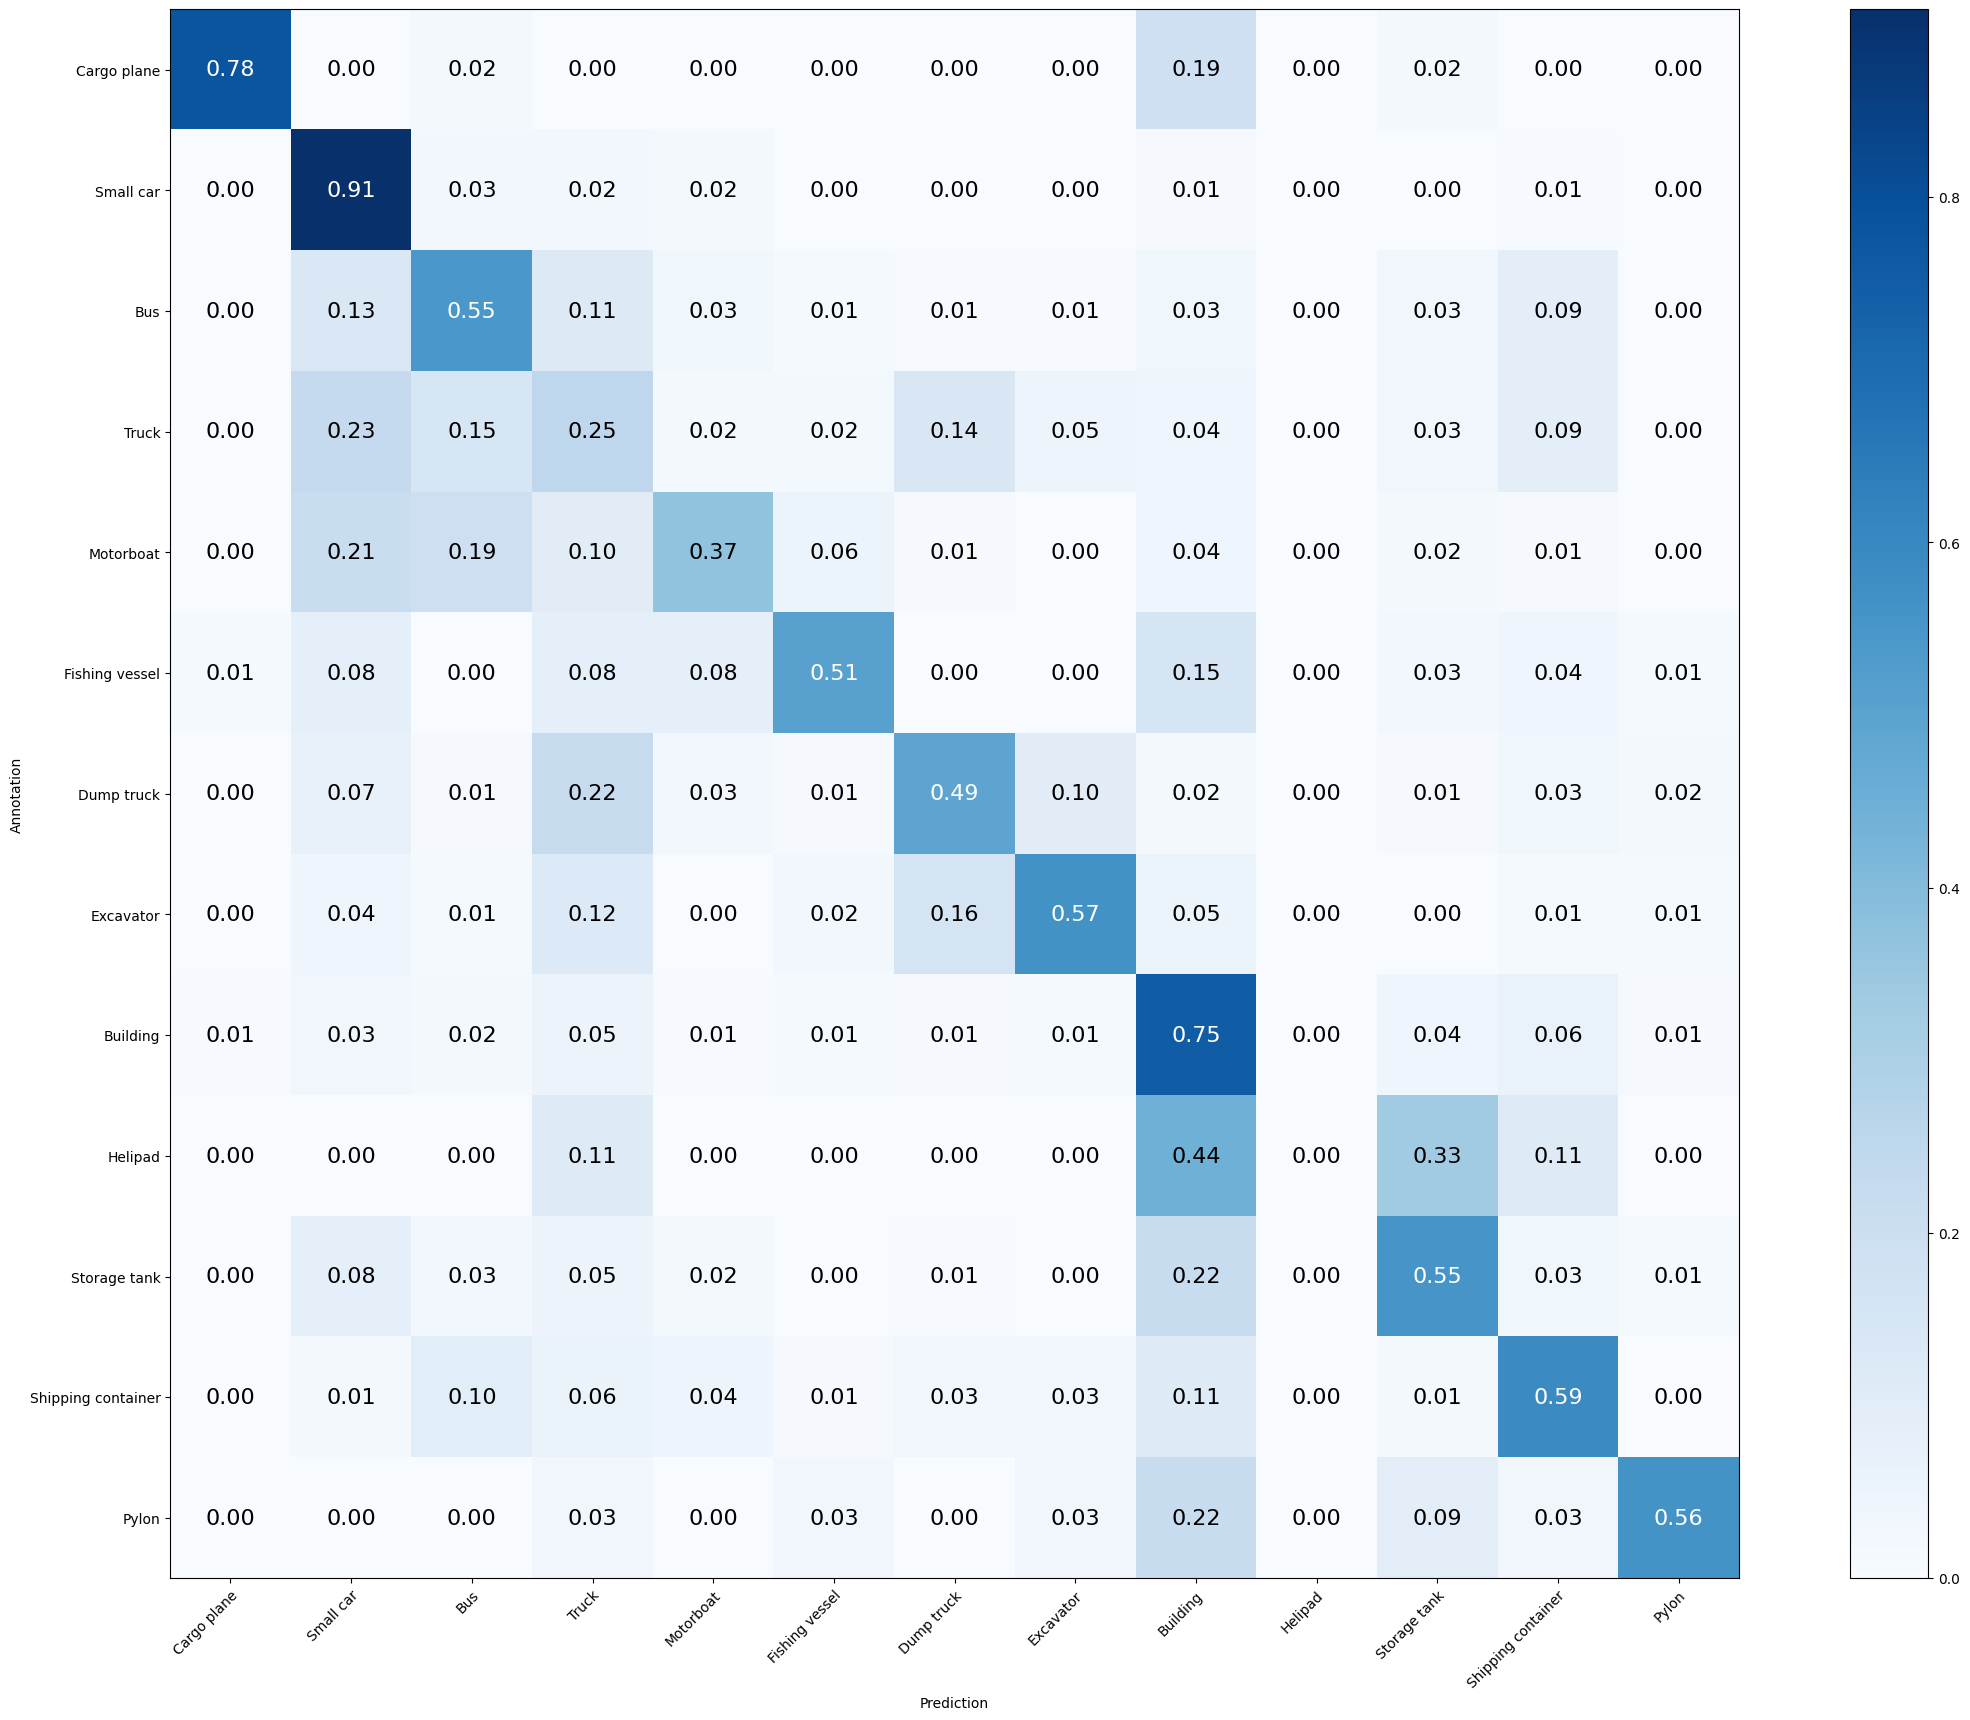

In [16]:
from sklearn.metrics import confusion_matrix

# Compute the confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=list(categories.values()))
draw_confusion_matrix(cm, categories)

In [17]:
import numpy as np

# Compute the accuracy
correct_samples_class = np.diag(cm).astype(float)
total_samples_class = np.sum(cm, axis=1).astype(float)
total_predicts_class = np.sum(cm, axis=0).astype(float)
print('Mean Accuracy: %.3f%%' % (np.sum(correct_samples_class) / np.sum(total_samples_class) * 100))
acc = correct_samples_class / np.maximum(total_samples_class, np.finfo(np.float64).eps)
print('Mean Recall: %.3f%%' % (acc.mean() * 100))
acc = correct_samples_class / np.maximum(total_predicts_class, np.finfo(np.float64).eps)
print('Mean Precision: %.3f%%' % (acc.mean() * 100))
for idx in range(len(categories)):
    # True/False Positives (TP/FP) refer to the number of predicted positives that were correct/incorrect.
    # True/False Negatives (TN/FN) refer to the number of predicted negatives that were correct/incorrect.
    tp = cm[idx, idx]
    fp = sum(cm[:, idx]) - tp
    fn = sum(cm[idx, :]) - tp
    tn = sum(np.delete(sum(cm) - cm[idx, :], idx))
    # True Positive Rate: proportion of real positive cases that were correctly predicted as positive.
    recall = tp / np.maximum(tp+fn, np.finfo(np.float64).eps)
    # Precision: proportion of predicted positive cases that were truly real positives.
    precision = tp / np.maximum(tp+fp, np.finfo(np.float64).eps)
    # True Negative Rate: proportion of real negative cases that were correctly predicted as negative.
    specificity = tn / np.maximum(tn+fp, np.finfo(np.float64).eps)
    # Dice coefficient refers to two times the intersection of two sets divided by the sum of their areas.
    # Dice = 2 |A∩B| / (|A|+|B|) = 2 TP / (2 TP + FP + FN)
    f1_score = 2 * ((precision * recall) / np.maximum(precision+recall, np.finfo(np.float64).eps))
    print('> %s: Recall: %.3f%% Precision: %.3f%% Specificity: %.3f%% Dice: %.3f%%' % (list(categories.values())[idx], recall*100, precision*100, specificity*100, f1_score*100))

Mean Accuracy: 60.533%
Mean Recall: 52.875%
Mean Precision: 55.831%
> Cargo plane: Recall: 77.966% Precision: 93.878% Specificity: 99.835% Dice: 85.185%
> Small car: Recall: 90.881% Precision: 67.647% Specificity: 90.750% Dice: 77.562%
> Bus: Recall: 54.598% Precision: 51.075% Specificity: 94.650% Dice: 52.778%
> Truck: Recall: 24.896% Precision: 33.708% Specificity: 92.778% Dice: 28.640%
> Motorboat: Recall: 36.697% Precision: 52.632% Specificity: 97.961% Dice: 43.243%
> Fishing vessel: Recall: 50.685% Precision: 62.712% Specificity: 98.779% Dice: 56.061%
> Dump truck: Recall: 49.153% Precision: 50.435% Specificity: 96.756% Dice: 49.785%
> Excavator: Recall: 56.790% Precision: 57.500% Specificity: 98.105% Dice: 57.143%
> Building: Recall: 74.931% Precision: 71.391% Specificity: 92.791% Dice: 73.118%
> Helipad: Recall: 0.000% Precision: 0.000% Specificity: 100.000% Dice: 0.000%
> Storage tank: Recall: 55.263% Precision: 67.200% Specificity: 97.620% Dice: 60.650%
> Shipping container: R

#### Testing
Try to improve the results provided in the competition.

In [18]:
import os
import numpy as np

anns = []
# CAMBIO DE RUTAS: recorrer el test desde DATA_DIR.
# for (dirpath, dirnames, filenames) in os.walk('../PROJECT/xview_recognition/xview_test'):
for (dirpath, dirnames, filenames) in os.walk(DATA_DIR / 'xview_test'):
    for filename in filenames:
        # CAMBIO DE RUTAS: ruta relativa al dataset, sin recortar caracteres.
        # image = GenericImage(dirpath[29:] + '/' + filename)
        relative_path = (Path(dirpath) / filename).relative_to(DATA_DIR)
        image = GenericImage(relative_path.as_posix())
        image.tile = np.array([0, 0, 224, 224])
        obj = GenericObject()
        obj.bb = (0, 0, 224, 224)
        obj.category = dirpath[dirpath.rfind('/')+1:]
        image.add_object(obj)
        anns.append(image)
print('Number of testing images: ' + str(len(anns)))

Number of testing images: 2365


In [19]:
# CAMBIO respecto a ffNN_example.ipynb: Precargar el test normalizado a 32 × 32 y predecir por lotes; conservar metadatos originales.
# Líneas sustituidas del original (fragmentos en su orden original):
#     image = load_geoimage(ann.filename)
#
#         warped_image = np.expand_dims(image, 0)
#         predictions = model.predict(warped_image, verbose=0)
#         pred_category = list(categories.values())[np.argmax(predictions)]

import numpy as np

# CAMBIO DE RUTAS: cargar el checkpoint del experimento 09 para el test.
# model.load_weights('model.keras')
model.load_weights(str(MODEL_PATH))
predictions_data = {"images": {}, "annotations": {}}
x_test = np.empty((len(anns), *IMAGE_SIZE, IMAGE_CHANNELS), dtype=np.float32)
for idx, ann in enumerate(anns):
    x_test[idx] = load_geoimage(ann.filename)
test_predictions = model.predict(x_test, batch_size=batch_size, verbose=0)

for idx, ann in enumerate(anns):
    image_data = {"image_id": ann.filename.split('/')[-1], "filename": ann.filename, "width": int(ann.tile[2]), "height": int(ann.tile[3])}
    predictions_data["images"][idx] = image_data
    for obj_pred in ann.objects:
        predictions = test_predictions[idx]
        pred_category = category_names[np.argmax(predictions)]
        pred_score = np.max(predictions)
        annotation_data = {"image_id": ann.filename.split('/')[-1], "category_id": pred_category, "bbox": [int(x) for x in obj_pred.bb]}
        predictions_data["annotations"][idx] = annotation_data


In [20]:
# CAMBIO DE RUTAS: escribir el JSON en experiment_09.
# with open("prediction.json", "w") as outfile:
with open(PREDICTION_PATH, "w") as outfile:
    json.dump(predictions_data, outfile)